# 02 — Exploratory Data Analysis

Churn patterns across customer segments, computed from the cleaned dataset. Every chart and number below is generated from the actual data.

In [1]:
import sys
sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from data_preprocessing import load_raw_data, clean_data
from feature_engineering import engineer_features

raw = load_raw_data('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df = engineer_features(clean_data(raw))
print(df.shape)


(7043, 32)


## Overall churn distribution

ChurnLabel
No     73.5
Yes    26.5
Name: proportion, dtype: float64


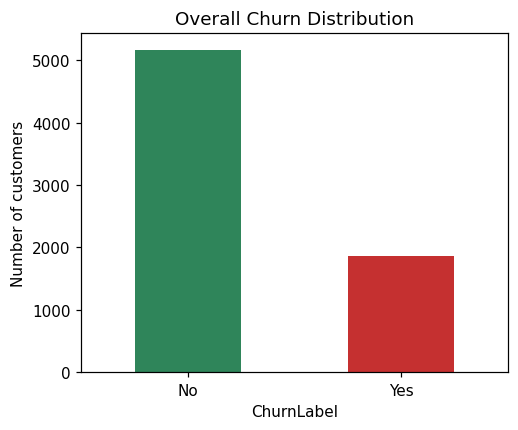

In [2]:
fig, ax = plt.subplots(figsize=(5,4))
df['ChurnLabel'].value_counts().plot(kind='bar', color=['#2f855a','#c53030'], ax=ax)
ax.set_title('Overall Churn Distribution')
ax.set_ylabel('Number of customers')
plt.xticks(rotation=0)
plt.show()
print(df['ChurnLabel'].value_counts(normalize=True).round(3) * 100)


**Business meaning:** roughly 1 in 4 customers in this book of business has churned historically — a meaningful revenue leak worth actively managing.

## Churn by contract type

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64


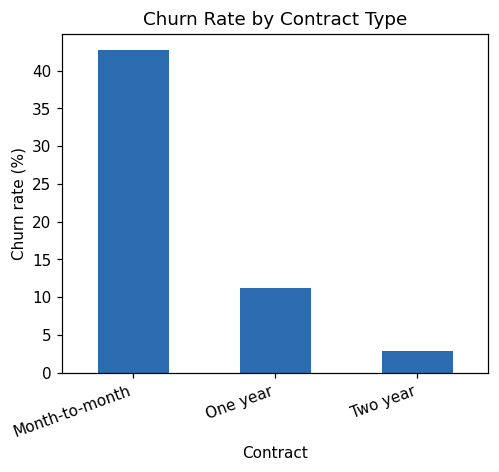

In [3]:
rate = df.groupby('Contract')['ChurnFlag'].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(5,4))
rate.plot(kind='bar', color='#2b6cb0', ax=ax)
ax.set_ylabel('Churn rate (%)')
ax.set_title('Churn Rate by Contract Type')
plt.xticks(rotation=20, ha='right')
plt.show()
print(rate.round(2))


**Business meaning:** month-to-month customers churn far more than annual/two-year customers — contract length is one of the strongest levers the business has (this shows up as the top feature in model importance too).

## Churn by tenure

TenureGroup
0-12 (New)             47.44
13-24 (Early)          28.71
25-48 (Established)    20.39
49-60 (Loyal)          14.42
61-72 (Veteran)         6.61
Name: ChurnFlag, dtype: float64


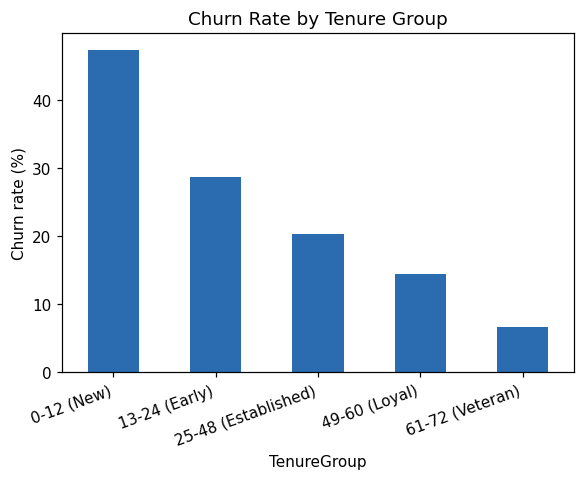

In [4]:
rate = df.groupby('TenureGroup', observed=True)['ChurnFlag'].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(6,4))
rate.plot(kind='bar', color='#2b6cb0', ax=ax)
ax.set_ylabel('Churn rate (%)')
ax.set_title('Churn Rate by Tenure Group')
plt.xticks(rotation=20, ha='right')
plt.show()
print(rate.round(2))


**Business meaning:** churn risk is heavily front-loaded in the first year of the relationship — the onboarding period is the highest-leverage window for retention effort.

## Churn by monthly charges

ChurnLabel
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


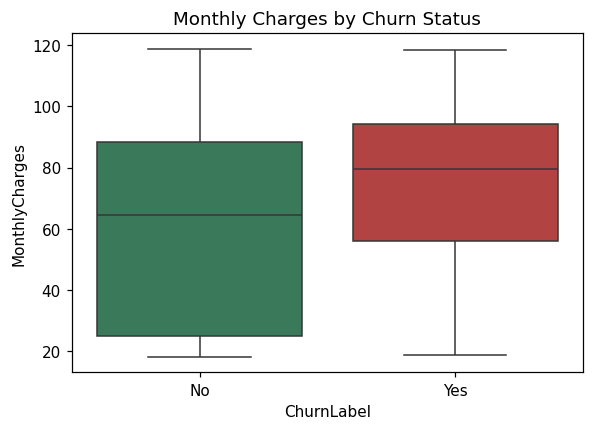

In [5]:
fig, ax = plt.subplots(figsize=(6,4))
sns.boxplot(data=df, x='ChurnLabel', y='MonthlyCharges', ax=ax, palette=['#2f855a','#c53030'])
ax.set_title('Monthly Charges by Churn Status')
plt.show()
print(df.groupby('ChurnLabel')['MonthlyCharges'].mean().round(2))


**Business meaning:** churned customers pay noticeably higher monthly charges on average — price sensitivity or perceived value-for-money is a plausible driver.

## Churn by payment method

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: ChurnFlag, dtype: float64


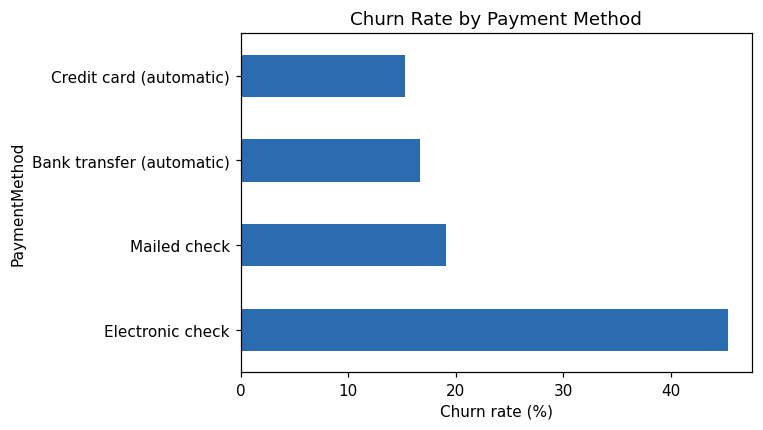

In [6]:
rate = df.groupby('PaymentMethod')['ChurnFlag'].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(6,4))
rate.plot(kind='barh', color='#2b6cb0', ax=ax)
ax.set_xlabel('Churn rate (%)')
ax.set_title('Churn Rate by Payment Method')
plt.show()
print(rate.round(2))


**Business meaning:** electronic check payers churn substantially more than customers on automatic payment methods — moving customers to autopay is a plausible low-cost retention lever.

## Churn by internet service

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: ChurnFlag, dtype: float64


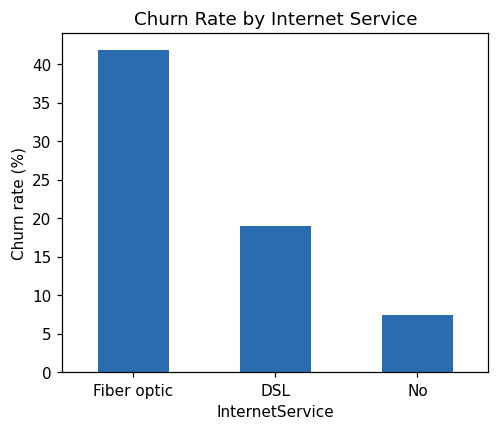

In [7]:
rate = df.groupby('InternetService')['ChurnFlag'].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(5,4))
rate.plot(kind='bar', color='#2b6cb0', ax=ax)
ax.set_ylabel('Churn rate (%)')
ax.set_title('Churn Rate by Internet Service')
plt.xticks(rotation=0)
plt.show()
print(rate.round(2))


**Business meaning:** fiber optic customers churn more than DSL or no-internet customers — worth investigating whether this reflects service quality issues, competitive pricing pressure, or simply a customer profile difference.

## Churn by senior citizen status

SeniorCitizenLabel
No     23.61
Yes    41.68
Name: ChurnFlag, dtype: float64


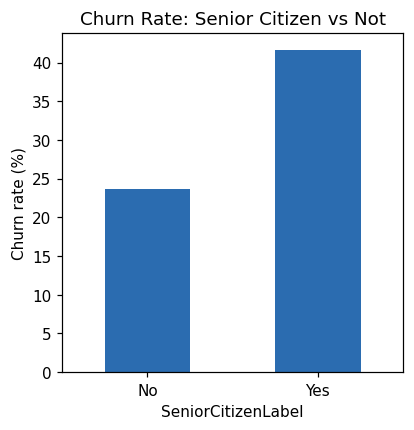

In [8]:
rate = df.groupby('SeniorCitizenLabel')['ChurnFlag'].mean() * 100
fig, ax = plt.subplots(figsize=(4,4))
rate.plot(kind='bar', color='#2b6cb0', ax=ax)
ax.set_ylabel('Churn rate (%)')
ax.set_title('Churn Rate: Senior Citizen vs Not')
plt.xticks(rotation=0)
plt.show()
print(rate.round(2))


## Churn by tech support

TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: ChurnFlag, dtype: float64


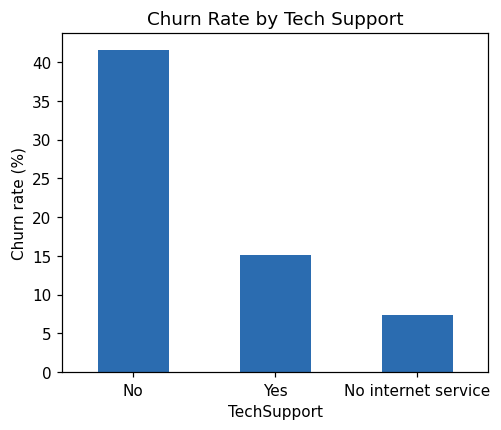

In [9]:
rate = df.groupby('TechSupport')['ChurnFlag'].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(5,4))
rate.plot(kind='bar', color='#2b6cb0', ax=ax)
ax.set_ylabel('Churn rate (%)')
ax.set_title('Churn Rate by Tech Support')
plt.xticks(rotation=0)
plt.show()
print(rate.round(2))


**Business meaning:** customers without tech support churn roughly 3x more than those with it — a strong candidate for a proactive retention offer.

## Churn by online security

OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: ChurnFlag, dtype: float64


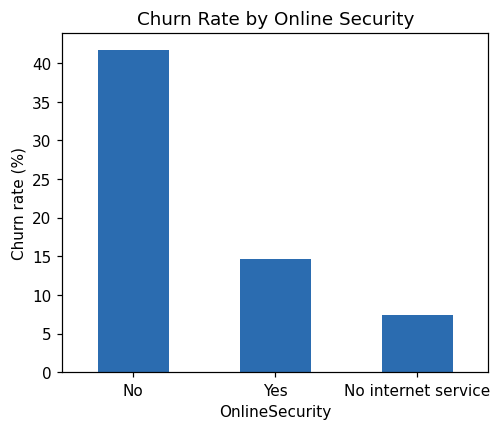

In [10]:
rate = df.groupby('OnlineSecurity')['ChurnFlag'].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(5,4))
rate.plot(kind='bar', color='#2b6cb0', ax=ax)
ax.set_ylabel('Churn rate (%)')
ax.set_title('Churn Rate by Online Security')
plt.xticks(rotation=0)
plt.show()
print(rate.round(2))


## Segment-wise summary table

In [11]:
summary = df.groupby('ChurnLabel').agg(
    avg_monthly_charges=('MonthlyCharges', 'mean'),
    avg_tenure=('tenure', 'mean'),
    avg_total_charges=('TotalCharges', 'mean'),
    n_customers=('customerID', 'count'),
).round(2)
print(summary)


            avg_monthly_charges  avg_tenure  avg_total_charges  n_customers
ChurnLabel                                                                 
No                        61.27       37.57            2549.91         5174
Yes                       74.44       17.98            1531.80         1869


## Key findings (business language)

1. **Contract type is the single clearest lever** — month-to-month
   customers churn at a much higher rate than annual/two-year customers.
2. **The first year is the danger zone** — churn risk drops sharply after
   ~12 months of tenure.
3. **Price matters** — churned customers pay more per month on average.
4. **Support & security add-ons correlate with retention** — customers
   without TechSupport or OnlineSecurity churn substantially more.
5. **Payment friction matters** — electronic check payers (a manual,
   non-automatic method) churn more than autopay customers.

These are **observed associations**, not proven causes — some (like
contract type) plausibly cause retention directly via switching cost;
others (like fiber optic churn) may reflect confounding customer profile
differences. Modeling in `04_model_training.ipynb` and feature importance
analysis help separate "what's associated" from "what the model actually
relies on to predict," but neither proves causation on its own.

Next: `03_feature_engineering.ipynb`.